# 06 统一图上的 Jev-as-IF：可行性检验

**要回答的问题**：把 `finmcp-graph` 的统一图交给 agent 作为接口，让它一次写出调用工具的程序，程序里需要语义判断的地方交给 Jev 执行。这条路在 FinMCP 筛选子集上站不站得住？

统一图包括对象本体和操作本体，动作的每个输入、输出都是"对象.属性"。

论文方法有三个环节，本 notebook 能检验到的程度不同：

| 环节 | 本 notebook 怎么检验 | 需要 |
| --- | --- | --- |
| 图能不能表达任务 | 用参考轨迹做静态分析（§2） | 不需要模型 |
| Jev 能不能做对程序里的判断 | 203 道判断题，4 种图信息用法，对比 3 个启发式基线；再看金标准本身是否可靠（§3–§5） | Jev |
| agent 能不能照着图写对程序 | 手写一个程序代替 agent，在回放环境里端到端执行（§6）。真正由大模型来写，需要大模型 key（§7） | 大模型 |

**运行**
- Jev key 先读环境变量，没有再读 `keys.py`。
- Jev 的结果缓存在 `cache/jev_onto/`，重跑不再花钱。
- 首次全部跑完约 813 次 Jev 请求、约 240 万输入 token，共约 0.10 美元。

In [1]:
import json, collections, statistics as stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from jif import config, onto, finmcp

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
CJK = next((n for n in ["PingFang SC", "Hiragino Sans GB", "Heiti SC", "Microsoft YaHei", "SimHei",
                        "Noto Sans CJK SC", "Source Han Sans SC", "Arial Unicode MS"]
            if n in {f.name for f in font_manager.fontManager.ttflist}), None)
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [CJK] if CJK else ["DejaVu Sans"], "axes.unicode_minus": False,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e7e6e1",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.dpi": 110,
})
INK, ACCENT, MUTED = "#2f69b8", "#c06a00", "#9aa7b4"

KEYS = config.load_keys()
print("Jev key：", "已设置" if KEYS["TYPESAFE_API_KEY"] else "未设置（只能读取缓存结果）")
print("大模型 key：", "已设置" if KEYS["LLM_API_KEY"] else "未设置（§7 跳过）")

O = onto.Onto()
UNITS = onto.load_units()
U = {u["id"]: u for u in UNITS}
DEC = onto.load_decisions()
REQ = {k: onto.request_text(u) for k, u in U.items()}
print(f"筛选子集：{len(UNITS)} 个单元，{len(DEC)} 道判断题；统一图：{len(O.objects)} 个对象，{len(O.actions)} 个动作")

Jev key： 已设置
大模型 key： 未设置（§7 跳过）
筛选子集：324 个单元，203 道判断题；统一图：25 个对象，52 个动作


## 1. agent 看到的接口

统一图渲染成一段文字，作为 agent 写程序时的接口说明，内容有：
- 对象和它们的属性、对象之间的关系；
- 每个动作的参数和输出。

参数名就是本体属性，所以程序里的数据依赖可以按"对象.属性"静态检查：某个参数要的 `Fund.fundCode`，必须来自某个产出 `Fund.fundCode` 的动作，或者来自客户原话。

In [2]:
ITF = O.interface()
print(f"接口文字 {len(ITF):,} 字符，约 {len(ITF) / 1.6:,.0f} token（中文按 1.6 字符/token 粗估）")
lines = ITF.splitlines()
start = next(i for i, l in enumerate(lines) if l.startswith("# 动作"))
print("\n".join(lines[:6] + ["……"] + lines[start:start + 8] + ["……"]))
print("\n".join(l for l in lines if l.startswith(("BatchGetStrategiesComposition", "BatchGetFundsFeeRule"))))

接口文字 21,954 字符，约 13,721 token（中文按 1.6 字符/token 粗估）
# 对象（对象.属性 是动作输入输出的唯一名字）
Customer（客户）：customerId=客户标识；userName=用户名；realName=真实姓名；gender=性别原码；registeredAt=注册时间；investDays=在平台的投资天数
  规则：证件号码等敏感身份信息不在回答中复述。
  规则：客户标识只能来自可信会话；同一次会话只服务同一位客户，不查询其他客户的数据。
Account（账户）：accountId=账户标识；accountName=账户名称；accountType=账户类型原码
  规则：账户标识须取自资产视图等已返回结果，不从用户话语或名称猜测。
……
# 动作（工具）
GetCurrentTime（获取当前时间）() -> MarketCalendar.{currentTime,weekday}
  规则：相对时间都以这里的当前时间换算。
GetTxnDayRange（推算交易日）(beforeDays: MarketCalendar.beforeDays, afterDays: MarketCalendar.afterDays, centerTime: MarketCalendar.centerTime, fundCode: Fund.fundCode) -> MarketCalendar.{tradingDays}
  规则：交易日按接口推算，不自行按自然日加减。
GetUserInfo（查询用户基本信息）(customerId: Customer.customerId（会话注入）) -> Customer.{userName,realName,gender,registeredAt}
  规则：只用于确认身份与称呼，证件信息不复述。
GetUserInvestDays（查询用户投资天数）(customerId: Customer.customerId（会话注入）) -> Customer.{investDays}
……
BatchGetStrategiesComposition（批量查询投顾策略的持有成分）(strategyCode: Strategy.strategyCode) -> Strategy.{stra

## 2. 图能不能表达任务（静态分析，不调用模型）

对每个单元的参考轨迹，把每个工具参数归入四类之一：
- **会话注入**：客户标识；
- **原话或常量**：客户原话里给出的值，或固定参数；
- **上游直接引用**：上游返回中只有一个候选；
- **上游挑选**：上游返回了多个候选、只用其中一部分，这就是 Jev 的判断点。

如果每一条"上游返回值 → 下游参数"都落在图上同一个属性的产出方和消费方之间，就说这条轨迹**能用图表达**。

**调用次数和阅读量**
- ReAct 每一轮都要把越来越长的对话重读一遍。
- 编译式只需两次大模型调用：读接口写程序一次，读结果作答一次。
- 下面按字符统计大模型要读的内容，不涉及具体分词器。

In [3]:
P = pd.DataFrame([O.unit_profile(u) for u in UNITS])
P["expressible"] = P["uncovered"] == 0
P["compiled_chars"] = len(ITF) + P["context_chars"] + (P["context_chars"] + P["results_chars"])
P["compiled_chars_no_itf"] = P["context_chars"] + (P["context_chars"] + P["results_chars"])
g = P.groupby("group")
summary = pd.DataFrame({
    "单元": g.size(),
    "能用图表达": g["expressible"].mean().map("{:.1%}".format),
    "工具调用（均值）": g["n_calls"].mean().round(1),
    "ReAct 大模型轮数（均值）": g["rounds"].mean().round(1),
    "判断点（均值）": g["selection_points"].mean().round(2),
    "直接引用点（均值）": g["reference_points"].mean().round(2),
    "ReAct 阅读量（中位，千字符）": (g["react_chars"].median() / 1000).round(1),
    "编译式阅读量，含接口（中位）": (g["compiled_chars"].median() / 1000).round(1),
    "编译式阅读量，不含接口（中位）": (g["compiled_chars_no_itf"].median() / 1000).round(1),
}).reindex(["D", "M", "I"])
summary.index = summary.index.map({"D": "D 含语义判断", "M": "M 只有机械依赖", "I": "I 无依赖"})
summary

,单元,能用图表达,工具调用（均值）,ReAct 大模型轮数（均值）,判断点（均值）,直接引用点（均值）,ReAct 阅读量（中位，千字符）,编译式阅读量，含接口（中位）,编译式阅读量，不含接口（中位）
group,,,,,,,,,
D 含语义判断,117,94.0%,8.0,7.9,3.33,1.82,179.7,74.4,52.4
M 只有机械依赖,173,96.0%,5.4,5.5,0.87,2.08,21.2,33.2,11.2
I 无依赖,34,100.0%,5.3,2.6,0.00,0.00,20.1,39.4,17.5


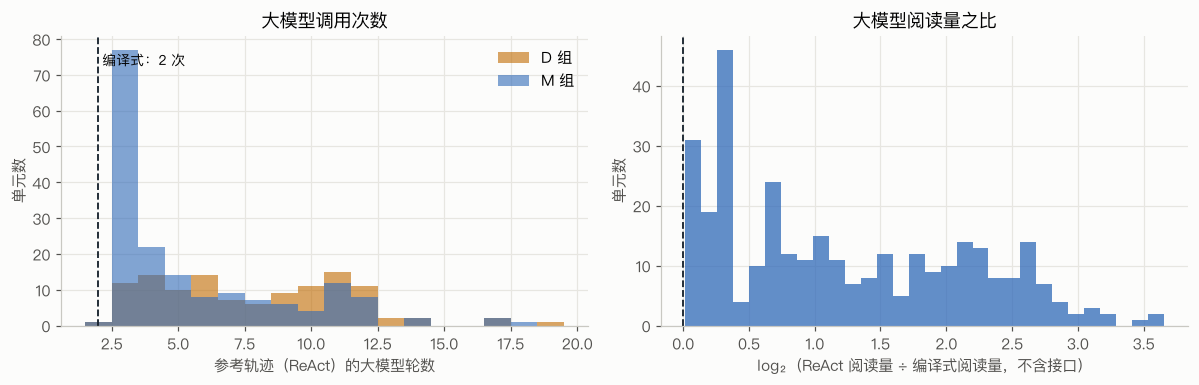

能用图表达：95.7%（310/324）；阅读量之比（不含接口）中位数 2.05，含接口 0.90
不能完整表达的单元（图外的依赖）： ['multi_tool:5', 'multi_tool:67', 'multi_tool:89', 'multi_tool:117', 'multi_tool:118', 'multi_tool:149', 'multi_tool:191', 'multi_tool:195', 'multi_tool:200', 'multi_tool:209', 'multi_turn:88#t3', 'multi_turn:103#t3', 'multi_turn:126#t4', 'multi_turn:187#t1']


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
bins = np.arange(1.5, P["rounds"].max() + 1.5)
for grp, color in [("D", ACCENT), ("M", INK)]:
    ax.hist(P.loc[P.group == grp, "rounds"], bins=bins, alpha=0.6, color=color, label=f"{grp} 组")
ax.axvline(2, color="#16212c", lw=1.2, ls="--")
ax.text(2.15, ax.get_ylim()[1] * 0.9, "编译式：2 次", fontsize=9)
ax.set(xlabel="参考轨迹（ReAct）的大模型轮数", ylabel="单元数", title="大模型调用次数")
ax.legend(frameon=False)
ax = axes[1]
ratio = P["react_chars"] / P["compiled_chars_no_itf"]
ax.hist(np.log2(ratio.clip(lower=1 / 8, upper=64)), bins=30, color=INK, alpha=0.75)
ax.axvline(0, color="#16212c", lw=1.2, ls="--")
ax.set(xlabel="log₂（ReAct 阅读量 ÷ 编译式阅读量，不含接口）", ylabel="单元数", title="大模型阅读量之比")
plt.tight_layout()
plt.show()
print(f"能用图表达：{P.expressible.mean():.1%}（{P.expressible.sum()}/{len(P)}）；"
      f"阅读量之比（不含接口）中位数 {ratio.median():.2f}，含接口 {(P.react_chars / P.compiled_chars).median():.2f}")
print("不能完整表达的单元（图外的依赖）：", P.loc[~P.expressible, "id"].tolist())

**怎么读**

- 能用图表达的比例，就是 `finmcp-graph` 里 99.5% 数据流覆盖率在单元层面的体现。
- **大模型调用次数**：参考轨迹平均要 4–5 轮，编译式固定为 2 次，再加上可能的修复。这是延迟上最确定的收益。
- **阅读量**：
  - 接口文字约 2.2 万字符。对短任务来说，它和 ReAct 的阅读量差不多。
  - 但接口是固定前缀，可以用提示缓存。缓存命中时，价格通常是正常输入的 1/10 左右。
  - 所以不含接口的那一列更能反映边际成本。
  - 要进一步压缩，可以按对象范围只披露相关部分，也就是 v0.4 的 `disclosure.hops`。

## 3. Jev 能不能做对判断点

每道判断题包含：
- 客户请求；
- 上游返回的候选记录；
- 参考轨迹实际选中的值，即金标准。

**题型**
- **选一个**（87 道）：用一次 Choice。
- **选一部分**（116 道）：对每个候选问一道 Noul，同一请求一次问完。

**4 种图信息用法**（消融"图对判断的贡献"）

| 变体 | 候选怎么呈现 | 问题怎么问 |
| --- | --- | --- |
| `plain` | 原始记录 JSON（截断到 600 字符） | 通用问法："根据客户的请求，应该选哪一个？" |
| `fields` | 只保留映射过的字段，并按属性含义改名（图来剪枝、命名） | 通用问法 |
| `graph` | 同 `fields` | 加上下游动作和所需属性，如："下一步要「批量查询基金费率」，需要基金的基金代码（Fund.fundCode）" |
| `graph+rules` | 同 `fields` | 同 `graph`，再附上对象和动作的规则 |

**基线**
- 随机；
- 取第一个候选（检索结果的排序）；
- 字面重合（请求和候选文本的二元字重合度）。

**指标**
- 选一个：准确率。
- 选一部分：
  - F1，阈值在开发集上调；
  - P@|gold|：按得分取前 |gold| 个时的准确率，相当于告诉方法该选几个，只看排序。
- 开发集（41 道）只用来调阈值，报告以测试集（162 道）为准。

In [5]:
J = onto.JevJudge(O)
VARIANTS = list(J.VARIANTS)
RES = {v: {r["decision_id"]: r for r in J.run(DEC, REQ, v, workers=8)} for v in VARIANTS}
spent = sum(r["tokens"] for v in VARIANTS for r in RES[v].values())
fresh = sum(not r["cached"] for v in VARIANTS for r in RES[v].values())
print(f"Jev 请求 {len(VARIANTS) * len(DEC)} 次（本次新发 {fresh} 次），输入 {spent:,} token，"
      f"约 ${spent / 1e6 * onto.PRICE_PER_MTOK:.3f}")

Jev 请求 812 次（本次新发 0 次），输入 2,392,507 token，约 $0.100


In [6]:
def cand(d):
    keys, recs = [], {}
    for c in d["candidates"]:
        k = finmcp.norm(c[d["id_key"]]) if d["id_key"] and isinstance(c, dict) else finmcp.norm(c)
        if k not in recs:
            keys.append(k)
            recs[k] = c
    return keys, recs

def bigrams(s):
    return {s[i:i + 2] for i in range(len(s) - 1)}

def lexical(d):
    keys, recs = cand(d)
    r = bigrams(REQ[d["unit_id"]])
    def sc(k):
        t = json.dumps(recs[k], ensure_ascii=False) if isinstance(recs[k], dict) else str(recs[k])
        b = bigrams(t)
        return len(r & b) / (len(b) ** 0.5 + 1)
    return {k: sc(k) for k in keys}

SCORES = {v: {d["decision_id"]: RES[v][d["decision_id"]]["score"] for d in DEC} for v in VARIANTS}
SCORES["首个候选"] = {d["decision_id"]: {k: -i for i, k in enumerate(cand(d)[0])} for d in DEC}
SCORES["字面重合"] = {d["decision_id"]: lexical(d) for d in DEC}

def f1(pred, gold):
    pred, gold = set(pred), set(gold)
    tp = len(pred & gold)
    return 1.0 if not pred and not gold else (2 * tp / (len(pred) + len(gold)) if tp else 0.0)

def top(score, k):
    return sorted(score, key=lambda x: -score[x])[:k]

def norm_scores(score):
    hi, lo = max(score.values()), min(score.values())
    return {k: (v - lo) / (hi - lo) if hi > lo else 1.0 for k, v in score.items()}

def subset_pred(method, d, t):
    s = SCORES[method][d["decision_id"]]
    s = s if method in VARIANTS else norm_scores(s)
    return [k for k, v in s.items() if v >= t]

GRID = np.round(np.arange(0.05, 0.96, 0.05), 2)
def tune(method):
    dev = [d for d in DEC if d["kind"] == "pick_subset" and d["split"] == "dev"]
    return max(GRID, key=lambda t: (np.mean([f1(subset_pred(method, d, t), d["gold"]) for d in dev]), -abs(t - 0.5)))

THRESH = {m: tune(m) for m in SCORES}

def evaluate(method, ds):
    one = [d for d in ds if d["kind"] == "pick_one"]
    sub = [d for d in ds if d["kind"] == "pick_subset"]
    S = SCORES[method]
    row = {"选一个 准确率": np.mean([top(S[d["decision_id"]], 1)[0] in d["gold"] for d in one]),
           "选一部分 P@|gold|": np.mean([len(set(top(S[d["decision_id"]], len(d["gold"]))) & set(d["gold"])) / len(d["gold"]) for d in sub]),
           "选一部分 F1（开发集阈值）": np.mean([f1(subset_pred(method, d, THRESH[method]), d["gold"]) for d in sub]),
           "阈值": THRESH[method]}
    if method in VARIANTS:
        row["选一部分 F1（阈值 0.5）"] = np.mean([f1(subset_pred(method, d, 0.5), d["gold"]) for d in sub])
    return row

TEST = [d for d in DEC if d["split"] == "test"]
table = pd.DataFrame({m: evaluate(m, TEST) for m in SCORES}).T
one_t = [d for d in TEST if d["kind"] == "pick_one"]
sub_t = [d for d in TEST if d["kind"] == "pick_subset"]
table.loc["随机（期望）"] = {"选一个 准确率": np.mean([1 / len(cand(d)[0]) for d in one_t]),
                         "选一部分 P@|gold|": np.mean([len(d["gold"]) / len(cand(d)[0]) for d in sub_t])}
table.loc["全选"] = {"选一部分 F1（开发集阈值）": np.mean([f1(cand(d)[0], d["gold"]) for d in sub_t])}
print(f"测试集：选一个 {len(one_t)} 道，选一部分 {len(sub_t)} 道")
table.astype(float).round(3)

测试集：选一个 73 道，选一部分 89 道


,选一个 准确率,选一部分 P@|gold|,选一部分 F1（开发集阈值）,阈值,选一部分 F1（阈值 0.5）
plain,0.630,0.550,0.541,0.10,0.140
fields,0.589,0.541,0.568,0.05,0.150
graph,0.658,0.588,0.566,0.05,0.267
graph+rules,0.616,0.517,0.563,0.05,0.166
首个候选,0.493,0.496,0.550,0.05,NaN
字面重合,0.356,0.422,0.407,0.15,NaN
随机（期望）,0.274,0.430,NaN,NaN,NaN
全选,NaN,NaN,0.565,NaN,NaN


In [7]:
lat = pd.DataFrame([{"variant": v, "kind": d["kind"], "n": d["n"], "latency": RES[v][d["decision_id"]]["latency"],
                     "tokens": RES[v][d["decision_id"]]["tokens"]} for v in VARIANTS for d in DEC])
cost = lat.groupby(["variant", "kind"]).agg(延迟中位_秒=("latency", "median"), 延迟P90_秒=("latency", lambda x: x.quantile(0.9)),
                                            输入token中位=("tokens", "median"))
cost["每题成本_美元"] = cost["输入token中位"] / 1e6 * onto.PRICE_PER_MTOK
display(cost.round(4))

# accuracy by candidate count, graph variant vs first-candidate, pick-one only
one_all = [d for d in DEC if d["kind"] == "pick_one"]
bins = [(2, 3), (4, 8), (9, 20), (21, 255)]
rows = []
for lo, hi in bins:
    ds = [d for d in one_all if lo <= d["n"] <= hi]
    rows.append({"候选数": f"{lo}–{hi}", "题数": len(ds),
                 **{m: np.mean([top(SCORES[m][d["decision_id"]], 1)[0] in d["gold"] for d in ds]) for m in ["graph", "plain", "首个候选", "字面重合"]}})
pd.DataFrame(rows).set_index("候选数").round(2)

延迟中位_秒  延迟P90_秒  输入token中位  每题成本_美元
variant     kind                                            
fields      pick_one     1.1263   3.6261     1167.0   0.0000
            pick_subset  1.3457   3.4659     2424.5   0.0001
graph       pick_one     0.9564   3.3916     1197.0   0.0001
            pick_subset  1.3381   3.7946     2829.0   0.0001
graph+rules pick_one     0.9263   2.2717     1300.0   0.0001
            pick_subset  1.7654   3.8424     3544.0   0.0001
plain       pick_one     1.2292   3.8323     1266.0   0.0001
            pick_subset  1.3750   3.8199     2729.0   0.0001

,题数,graph,plain,首个候选,字面重合
候选数,,,,,
2–3,35,0.71,0.69,0.63,0.46
4–8,25,0.48,0.48,0.44,0.24
9–20,24,0.71,0.67,0.38,0.25
21–255,3,0.67,0.33,0.00,0.00


**门控：Jev 没把握的时候交给谁？**

编译式执行里，Jev 每做一个判断都会给出概率。
- 把握不够的判断交给大模型（回退），其余的直接用。
- 下图是"选一个"题在测试集上的取舍：横轴是 Jev 直接作答的比例（覆盖率），纵轴是这些作答的准确率。

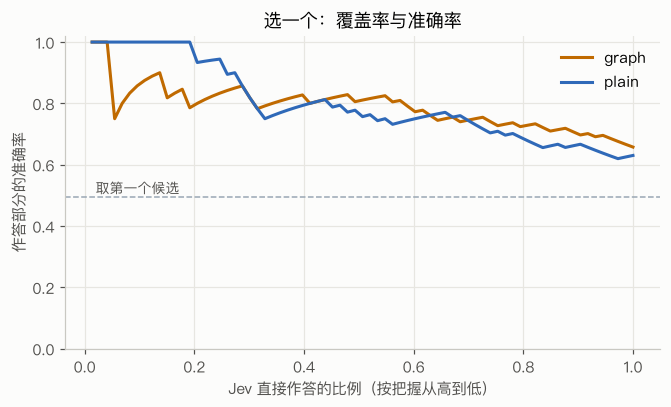

In [8]:
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for v, color in [("graph", ACCENT), ("plain", INK)]:
    pts = []
    for d in one_t:
        r = RES[v][d["decision_id"]]
        pts.append((r["p_top"], r["pred"][0] in d["gold"]))
    pts.sort(key=lambda x: -x[0])
    cov = np.arange(1, len(pts) + 1) / len(pts)
    acc = np.cumsum([c for _, c in pts]) / np.arange(1, len(pts) + 1)
    ax.plot(cov, acc, color=color, lw=2, label=v)
ax.axhline(np.mean([cand(d)[0][0] in d["gold"] for d in one_t]), color=MUTED, ls="--", lw=1)
ax.text(0.02, np.mean([cand(d)[0][0] in d["gold"] for d in one_t]) + 0.015, "取第一个候选", color="#52514e", fontsize=9)
ax.set(xlabel="Jev 直接作答的比例（按把握从高到低）", ylabel="作答部分的准确率", ylim=(0, 1.02), title="选一个：覆盖率与准确率")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**换一种问法**

"选一部分"时逐项问 Noul，每道题只看到一个候选，候选之间无法比较。这里改成对全部候选问一次 Choice，再按概率排序，看排序质量会不会更好。

In [9]:
def choice_rank(d):
    dd = dict(d, kind="pick_one")
    state, qs, keys_ = J.build(dd, REQ[d["unit_id"]], "graph")
    q = qs["pick"]
    instr = q[1].replace("应该选哪一个？", "客户要的是哪些？给每个候选分配概率，越符合客户要求的概率越高。")
    out = J._ask(state, {"pick": ("choice", instr, q[2])})
    return {k: out["choices"]["pick"].get(k, 0) for k in keys_}

SCORES["graph·一次Choice"] = {d["decision_id"]: choice_rank(d) for d in DEC if d["kind"] == "pick_subset"}
sub_t = [d for d in TEST if d["kind"] == "pick_subset"]
for m in ["graph", "graph·一次Choice", "首个候选"]:
    print(f"{m:<16} 选一部分 P@|gold|（测试集）{np.mean([len(set(top(SCORES[m][d['decision_id']], len(d['gold']))) & set(d['gold'])) / len(d['gold']) for d in sub_t]):.3f}")

graph            选一部分 P@|gold|（测试集）0.588
graph·一次Choice   选一部分 P@|gold|（测试集）0.595
首个候选             选一部分 P@|gold|（测试集）0.496


## 4. 金标准本身有多可靠

FinMCP 的多工具轨迹是 Qwen3-235B 按工具依赖图合成的。如果"选一部分"的金标准只是"取前 k 个"，那么这道题考的不是语义判断，而是有没有模仿出生成模型的截断习惯。

下面统计金标准落在候选列表开头的比例，再把题目分成两类，分别看各方法的表现：
- **前缀型**：金标准正好是前 k 个；
- **非前缀型**：更可能是真正按语义挑选的。

In [10]:
def is_prefix(d):
    keys = cand(d)[0]
    return set(d["gold"]) == set(keys[:len(d["gold"])])

one_all = [d for d in DEC if d["kind"] == "pick_one"]
sub_all = [d for d in DEC if d["kind"] == "pick_subset"]
print(f"选一个：金标准是第一个候选的占 {np.mean([is_prefix(d) for d in one_all]):.1%}")
print(f"选一部分：金标准正好是前 k 个的占 {np.mean([is_prefix(d) for d in sub_all]):.1%}")

rows = []
for name, ds in [("前缀型", [d for d in sub_all if is_prefix(d)]), ("非前缀型", [d for d in sub_all if not is_prefix(d)])]:
    rows.append({"选一部分": name, "题数": len(ds),
                 **{m: np.mean([len(set(top(SCORES[m][d["decision_id"]], len(d["gold"]))) & set(d["gold"])) / len(d["gold"]) for d in ds])
                    for m in ["graph", "plain", "首个候选", "字面重合"]}})
for name, ds in [("前缀型", [d for d in one_all if is_prefix(d)]), ("非前缀型", [d for d in one_all if not is_prefix(d)])]:
    rows.append({"选一部分": "选一个 · " + name, "题数": len(ds),
                 **{m: np.mean([top(SCORES[m][d["decision_id"]], 1)[0] in d["gold"] for d in ds]) for m in ["graph", "plain", "首个候选", "字面重合"]}})
print("指标：选一部分为 P@|gold|，选一个为准确率（全部 203 道）")
pd.DataFrame(rows).set_index("选一部分").round(2)

选一个：金标准是第一个候选的占 48.3%
选一部分：金标准正好是前 k 个的占 14.7%
指标：选一部分为 P@|gold|，选一个为准确率（全部 203 道）


,题数,graph,plain,首个候选,字面重合
选一部分,,,,,
前缀型,17,0.69,0.69,1.0,0.64
非前缀型,99,0.56,0.51,0.4,0.41
选一个 · 前缀型,42,0.67,0.69,1.0,0.48
选一个 · 非前缀型,45,0.62,0.53,0.0,0.18


In [11]:
def show(d, method="graph", limit=10):
    keys, recs = cand(d)
    s = SCORES[method][d["decision_id"]]
    print(f"【{d['decision_id']} · {d['kind']} · {d['split']}】{U[d['unit_id']]['question'][:110]}")
    print(f"  {d['src_tool']} → {d['dst_tool']}.{d['dst_arg']}，{len(keys)} 个候选；★ 金标准，数字是 Jev（{method}）得分")
    for k in keys[:limit]:
        r = recs[k]
        name = next((v for kk, v in r.items() if isinstance(v, str) and any(t in kk for t in ("名称", "Name", "name", "title", "标题"))), "") if isinstance(r, dict) else ""
        print(f"   {'★' if k in d['gold'] else ' '} {s.get(k, 0):.2f}  {k}  {name}")
    if len(keys) > limit:
        print(f"   …… 另有 {len(keys) - limit} 个")

ex = [d for d in sub_all if is_prefix(d) and len(d["gold"]) >= 3][:1] + [d for d in sub_all if not is_prefix(d)][:1]
for d in ex:
    show(d)
    print()

【d0012 · pick_subset · test】其他五剑不收吗
当前用户id是9b989f989c9892
  BatchGetStrategiesComposition → BatchGetFundsFeeRule.fundCodes，23 个候选；★ 金标准，数字是 Jev（graph）得分
   ★ 0.22  012680  华泰柏瑞光伏ETF联接C
   ★ 0.18  018301  华夏消费电子ETF联接C
   ★ 0.27  018921  东方红中证东方红优势成长指数C
   ★ 0.21  012709  东方红中证红利低波动指数C
   ★ 0.24  011615  工银科创板50ETF联接C
   ★ 0.21  018099  方正富邦中证保险主题指数C
   ★ 0.24  018412  易方达中证芯片产业ETF联接C
   ★ 0.20  020516  华泰柏瑞东南亚科技ETF发起式联接(QDII)C
   ★ 0.26  013309  易方达恒生科技ETF联接(QDII)C
   ★ 0.22  022586  国泰中证钢铁ETF联接E
   …… 另有 13 个

【d0000 · pick_subset · test】投资国外市场的投顾组合
当前用户id是9b989c9c9e9e93
  StrategySearchByKeyword → GetStrategyDetails.strategyCodes，17 个候选；★ 金标准，数字是 Jev（graph）得分
   ★ 0.60  ZH158559  3收益目标资配方案-国内+商品+海外
     0.66  ZH158560  4收益目标资配方案-国内+商品+海外
     0.62  ZH158561  5收益目标资配方案-国内+商品+海外
     0.64  ZH158562  6收益目标资配方案-国内+商品+海外
     0.65  ZH158563  7收益目标资配方案-国内+商品+海外
     0.65  ZH158564  8收益目标资配方案-国内+商品+海外
     0.62  ZH158565  9收益目标资配方案-国内+商品+海外
     0.64  ZH158566  10收益目标资配方案-国内+商品+海外
   ★ 0.60 

## 5. 任务级：假设程序写对了

假设 agent 写出的程序结构和参考轨迹一致，那么一个单元能否成功，就取决于它的每个判断点是否都判对。规则如下：
- 选一个：要选中金标准；
- 选一部分：要和金标准完全一致，阈值用开发集上调出的值。

这是一个上界式的估计：
- 它不包括写程序出错的情况；
- 也继承了 §4 里金标准的问题。

In [12]:
by_unit = collections.defaultdict(list)
for d in DEC:
    by_unit[d["unit_id"]].append(d)

def unit_ok(method, ds):
    ok = True
    for d in ds:
        if d["kind"] == "pick_one":
            ok &= top(SCORES[method][d["decision_id"]], 1)[0] in d["gold"]
        else:
            ok &= set(subset_pred(method, d, THRESH[method])) == set(d["gold"])
    return ok

rows = []
for split in ["test", "dev"]:
    units = [u for u, ds in by_unit.items() if U[u]["split"] == split]
    rows.append({"划分": split, "单元": len(units),
                 **{m: np.mean([unit_ok(m, by_unit[u]) for u in units]) for m in ["graph", "plain", "fields", "graph+rules", "首个候选", "字面重合"]}})
tbl = pd.DataFrame(rows).set_index("划分")
methods = ["graph", "plain", "fields", "graph+rules", "首个候选", "字面重合"]
tbl[methods] = (tbl[methods] * 100).round(1)
print("单元全部判断都对的比例（%）")
display(tbl)

one_only = [u for u, ds in by_unit.items() if all(d["kind"] == "pick_one" for d in ds)]
print(f"只含'选一个'判断的单元 {len(one_only)} 个：graph 全对 {np.mean([unit_ok('graph', by_unit[u]) for u in one_only]):.1%}，"
      f"首个候选 {np.mean([unit_ok('首个候选', by_unit[u]) for u in one_only]):.1%}")
jl = [sum(RES["graph"][d["decision_id"]]["latency"] for d in ds) for ds in by_unit.values()]
print(f"每个单元的 Jev 总耗时（判断点顺序执行）：中位 {np.median(jl):.2f} 秒，P90 {np.quantile(jl, 0.9):.2f} 秒；"
      f"每单元 Jev 成本中位 ${np.median([sum(RES['graph'][d['decision_id']]['tokens'] for d in ds) for ds in by_unit.values()]) / 1e6 * onto.PRICE_PER_MTOK:.5f}")

单元全部判断都对的比例（%）


,单元,graph,plain,fields,graph+rules,首个候选,字面重合
划分,,,,,,,
test,93,22.6,23.7,21.5,23.7,12.9,10.8
dev,24,20.8,16.7,16.7,20.8,12.5,4.2


只含'选一个'判断的单元 37 个：graph 全对 70.3%，首个候选 37.8%
每个单元的 Jev 总耗时（判断点顺序执行）：中位 2.16 秒，P90 5.83 秒；每单元 Jev 成本中位 $0.00014


## 6. 端到端演示：照着统一图写的程序，在回放环境里执行

这里由我手写程序，代替 agent。程序只用统一图上的名字：
- **调用动作**：用动作 id 和参数名（参数名就是本体属性名）。
- **取出候选**：用 `rt.records(结果, 动作, "Fund.fundCode")`。哪个字段路径装着 `Fund.fundCode`，由映射文件决定，程序里不用写路径。
- **语义判断**：交给 Jev，候选按图的字段含义呈现。

任务是 `multi_tool:104`：筛选近一年业绩稳定、回撤控制好的医疗主题基金。
- 工具调用走回放存储。参数和参考轨迹一致时返回原始结果；不一致时返回最相近的记录。
- 检索参数照抄参考轨迹，这样回放能命中。

In [13]:
from jif.replay import ReplayStore
import time

STORE = ReplayStore(("multi_tool",))
TASK = "multi_tool:104"
request = U[TASK]["question"]
print(request)

PROGRAM = '''
funds = rt.call("SearchFunds", category="健康中国", pageNum=0)
codes = rt.values(funds, "SearchFunds", "Fund.fundCode")
perf = rt.call("GetBatchFundPerformance", fundCode=codes)
cands = rt.records(perf, "GetBatchFundPerformance", "Fund.fundCode")
picked, score, _ = jev.select(request, "这只基金近一年业绩是否稳定、回撤控制得好，值得进一步分析？",
                              cands, rt.describe(cands, "GetBatchFundPerformance", "Fund.fundCode"))
chosen = [c["fundCode"] for c in picked]
detail = rt.call("BatchGetFundsDetail", fundCode=chosen)
views = rt.call("SearchManagerViewpoint", keyword="医疗", startDate="2024-01-01", endDate="2025-08-15", pageNum=1, pageSize=5)
'''
print(PROGRAM)

rt = onto.Runtime(O, STORE, TASK)
env = {"rt": rt, "jev": J, "request": request}
t0 = time.perf_counter()
exec(PROGRAM, env)
wall = time.perf_counter() - t0
pd.DataFrame(rt.trace)

近期医疗板块调整较大，我想了解哪些医疗主题基金具有较好的抗风险能力和长期增长潜力。请帮我筛选出近一年业绩稳定且回撤控制良好的医疗基金，分析它们的投资策略，并结合基金经理对医疗行业的最新观点，评估当前是否是布局医疗板块的好时机。

funds = rt.call("SearchFunds", category="健康中国", pageNum=0)
codes = rt.values(funds, "SearchFunds", "Fund.fundCode")
perf = rt.call("GetBatchFundPerformance", fundCode=codes)
cands = rt.records(perf, "GetBatchFundPerformance", "Fund.fundCode")
picked, score, _ = jev.select(request, "这只基金近一年业绩是否稳定、回撤控制得好，值得进一步分析？",
                              cands, rt.describe(cands, "GetBatchFundPerformance", "Fund.fundCode"))
chosen = [c["fundCode"] for c in picked]
detail = rt.call("BatchGetFundsDetail", fundCode=chosen)
views = rt.call("SearchManagerViewpoint", keyword="医疗", startDate="2024-01-01", endDate="2025-08-15", pageNum=1, pageSize=5)



,action,args,replay,score,ms
0,SearchFunds,"{'category': '健康中国', 'page': 0}",hit,1.0,0.0
1,GetBatchFundPerformance,"{'fundCodes': ['000220', '000339', '000452', '000523', '000547', '000591', '000646', '...",hit,1.0,0.4
2,BatchGetFundsDetail,"{'fundCodes': ['000220', '000339', '000452', '000523', '000547', '000591', '000646', '...",miss,0.3,0.1
3,SearchManagerViewpoint,"{'keyword': '医疗', 'page': 1, 'pageSize': 5, 'startDate': '2024-01-01', 'endDate': '202...",hit,1.0,0.0


In [14]:
ref = [d for d in DEC if d["unit_id"] == TASK][0]
print("Jev 对每个候选的打分（≥0.5 选中），★ 为参考轨迹的选择：")
for i, c in enumerate(env["cands"]):
    p = env["score"][str(i)]
    print(f"  {'★' if c['fundCode'] in ref['gold'] else ' '} {p:.2f} {'选中' if p >= 0.5 else '    '}  {c['fundCode']}")
print(f"\nJev 选中 {env['chosen']}，参考轨迹选 {ref['gold']}")
jev_ms = env["_"]["latency"] * 1000
print(f"程序总耗时 {wall:.2f} 秒（其中 Jev {jev_ms:.0f} 毫秒{'，读的是缓存，耗时为首次请求时的记录' if env['_']['cached'] else ''}；回放工具几乎不耗时）")
print(f"参考轨迹（ReAct）用了 {U[TASK]['n_steps'] + 1} 轮大模型调用；编译式为写程序 1 次 + 作答 1 次")

Jev 对每个候选的打分（≥0.5 选中），★ 为参考轨迹的选择：
    0.59 选中  000220
    0.62 选中  000339
  ★ 0.64 选中  000452
  ★ 0.62 选中  000523
    0.61 选中  000547
    0.62 选中  000591
  ★ 0.67 选中  000646
    0.60 选中  000684
    0.53 选中  000711
    0.55 选中  000727

Jev 选中 ['000220', '000339', '000452', '000523', '000547', '000591', '000646', '000684', '000711', '000727']，参考轨迹选 ['000452', '000523', '000646']
程序总耗时 0.01 秒（其中 Jev 2888 毫秒，读的是缓存，耗时为首次请求时的记录；回放工具几乎不耗时）
参考轨迹（ReAct）用了 5 轮大模型调用；编译式为写程序 1 次 + 作答 1 次


## 7. 大模型基线：在判断点上用大模型代替 Jev

这是论文最关键的对照，即 "LLM-as-IF"：程序结构完全一样，只把判断交给大模型。它回答的问题是：Jev 在准确率上掉多少，在延迟和成本上省多少。

需要在 `keys.py` 里填 `LLM_API_KEY`（默认 DeepSeek）。没有 key 时本节跳过。

In [15]:
if KEYS["LLM_API_KEY"]:
    from jif.llm import LLM, Ledger
    llm = LLM(KEYS["LLM_BASE_URL"], KEYS["LLM_API_KEY"], KEYS["LLM_MODEL"] or "deepseek-chat", ledger=Ledger())
    LLMRES = {}
    for d in TEST:
        keys_, recs = cand(d)
        texts = {k: O.describe(d["src_tool"], d["src_path"], recs[k]) if isinstance(recs[k], dict) else k for k in keys_}
        LLMRES[d["decision_id"]] = onto.llm_select(llm, d, REQ[d["unit_id"]], texts)
    one = [d for d in TEST if d["kind"] == "pick_one"]
    sub = [d for d in TEST if d["kind"] == "pick_subset"]
    print(f"大模型 选一个 准确率 {np.mean([bool(LLMRES[d['decision_id']]['pred']) and LLMRES[d['decision_id']]['pred'][0] in d['gold'] for d in one]):.3f}")
    print(f"大模型 选一部分 F1 {np.mean([f1(LLMRES[d['decision_id']]['pred'], d['gold']) for d in sub]):.3f}")
    print(f"大模型 延迟中位 {np.median([r['latency'] for r in LLMRES.values()]):.2f} 秒")
else:
    print("没有大模型 key，跳过。")

没有大模型 key，跳过。


## 8. 结论：这条路站不站得住

以下数字都来自上面的运行结果。测试集指标以 §3 的表为准。

### 站得住的部分

**1. 图能表达任务**
- 324 个单元里，95.7% 的全部数据依赖都落在统一图上：上游产出的"对象.属性"，正是下游参数需要的那个属性。
- 不能完整表达的 14 个单元，多数是参考轨迹本身把编号用错了。

**2. 一次编译能省掉大部分轮次**
- D 组参考轨迹平均要 7.9 轮大模型调用，编译式固定为 2 次。
- 大模型要读的内容（不含可缓存的接口），D 组中位数从约 180 千字符降到约 52 千字符。
- 不过 M、I 组的短任务，如果每次都带上 2.2 万字符的完整接口，反而比 ReAct 读得多。所以按对象范围披露（`disclosure.hops`）和提示缓存是必需的，不是可选优化。

**3. Jev 便宜、快，图信息对它有帮助**
- 每个判断点的延迟中位约 1 秒，每个单元的 Jev 成本中位约 $0.00014。全部 813 次请求一共约 0.10 美元。
- "选一个"（测试集）：
  - 图构造问题的变体（graph）准确率 0.658；
  - 通用问法（plain）0.630；
  - 取第一个候选 0.493，随机 0.274。
- 在金标准不是第一个候选、更可能是真正按语义挑选的题上：graph 0.62，plain 0.53。
- "下游动作 + 所需属性"这种由图构造的问法确实有用。
- 但在门控曲线上，把握最高的 20% 里，通用问法反而校准得更好（准确率 1.0）。图构造问法的提升主要出现在中低把握区间。如果要把门控作为卖点，需要专门标定。

### 还站不住、或者还没证据的部分

**1. "选一部分"基本失败**
- 逐项问 Noul 时，得分挤在一起：开发集上调出的最佳阈值是 0.05，相当于全选。F1 0.566，与全选的 0.565 持平。
- 改成一次 Choice 排序，排序质量也几乎不变。
- 演示任务里 10 只基金全部被选中。"近一年业绩稳定、回撤控制好"是数值比较，应该由程序按回撤、波动率去算，不该交给 Jev。

**2. 附上规则反而变差**
- 对象和动作的规则是给 agent 的行为约束，不是判断标准。
- 附上后，Jev 会更多地回答"都不是"。

**3. 金标准不可靠**
- "选一个"的金标准有 48% 恰好是第一个候选。
- 很多"选一部分"的金标准看不出语义依据，例如 d0000：17 个海外相关策略里只取了 3 个。
- FinMCP 的合成轨迹不能直接当判断点的标准答案。按现在的金标准，任务级全对率只有约 23%；只含"选一个"判断的单元是 70%。

**4. 最关键的两个对照还没做**
- 判断点用大模型还是用 Jev（§7）；
- 由大模型真正照着图写程序的成功率。

### 对论文的判断

**这个 idea 值得写**，但目前的证据只支撑一半：
- **已有证据**："基于图一次编译 → 轮次和阅读量大幅下降"；
- **还缺证据**："Jev 让判断又准又省"。在"选一部分"上，现在甚至是反例。

要成文，需要四件事：

1. **重新标注判断点**：给每个判断点标出可接受的答案集合，不再用"和合成轨迹完全一致"做标准。117 个 D 组单元的审核工具已经备好。
2. **把判断点分类，写进方法**：
   - 语义匹配（客户指的是哪个产品、哪类策略）交给 Jev；
   - 数值筛选和排序由程序计算；
   - "全选""取前 k"由程序直接决定。

   编译器在静态阶段决定每个判断交给谁，这可以成为方法的核心贡献之一。
3. **做 LLM-as-IF 对照**：程序结构相同，只把判断换成大模型，再加上 ReAct 基线。
4. **端到端实验**：由大模型照着图写程序，统计成功率和修复次数。